In [1]:
## Exact Method

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("andrewmvd/sp-500-stocks")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Nishama.Vilochana\.cache\kagglehub\datasets\andrewmvd\sp-500-stocks\versions\1023


In [3]:
import pandas as pd

In [4]:
df_companies = pd.read_csv(f"{path}/sp500_companies.csv")
df_stocks    = pd.read_csv(f"{path}/sp500_stocks.csv",  parse_dates=['Date'])
df_index     = pd.read_csv(f"{path}/sp500_index.csv",   parse_dates=['Date'])

## Overview

**Problem.** From the S&P 500 stocks that have price data, choose **at most K** and decide the **weight** of each, so that portfolio risk is as low as possible while the expected daily return stays at or above a target. A held stock must carry a weight between a minimum and a maximum.

**This notebook is the exact method.** It formulates the problem as a **mixed-integer linear program (MILP)** and solves it with Branch and Bound (HiGHS through `scipy.optimize.milp`), which gives a *proven* optimum, a best bound and a gap. The heuristic half of the assignment will be compared against these results.

| Part | Content |
|---|---|
| 1 | Data understanding and preparation |
| 2 | Modelling choices and the mathematical formulation |
| 3 | Solver, worked example, validation against brute force |
| 4 | Experiments: LP-relaxation gap, scalability, effect of K, efficient frontier, naive baselines |
| 5 | Saved results, findings, hand-over to the heuristic half |

**Course links.** Formulation template: Lecture 1 slides 24-32. LP and the absolute-value split: Lecture 3 slides 6-28. Binary variables, LP relaxation, integrality gap and Branch and Bound: Lecture 5 slides 8-9, 23-39. Bound direction and duality: Lecture 4 slides 13-24. Portfolio example: Lecture 7 slide 52.

In [5]:
import time
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import milp, linprog, LinearConstraint, Bounds

SEED = 42
pd.set_option("display.precision", 5)
pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Data understanding

The three files were loaded above. Before modelling we check what the price file actually contains, because earlier assumptions about it need to be verified.

stocks table: (1891536, 8) | companies: (502, 16) | index: (2517, 2)
stock dates: 2010-01-04 -> 2024-12-20
symbols in the stocks table: 502
symbols with at least one price: 172
symbols with NO price at all   : 330
share of price rows that are empty: 67.3%


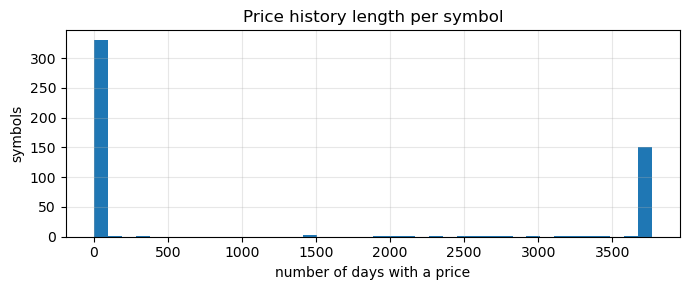

In [6]:
print("stocks table:", df_stocks.shape, "| companies:", df_companies.shape, "| index:", df_index.shape)
print("stock dates:", df_stocks["Date"].min().date(), "->", df_stocks["Date"].max().date())
print("symbols in the stocks table:", df_stocks["Symbol"].nunique())

valid_days = df_stocks.groupby("Symbol")["Adj Close"].count()
print(f"symbols with at least one price: {(valid_days > 0).sum()}")
print(f"symbols with NO price at all   : {(valid_days == 0).sum()}")
print(f"share of price rows that are empty: {df_stocks['Adj Close'].isna().mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(valid_days, bins=40)
ax.set_xlabel("number of days with a price")
ax.set_ylabel("symbols")
ax.set_title("Price history length per symbol")
plt.tight_layout()
plt.show()

**Finding.** Only part of the S&P 500 list has price history in this file; the rest of the rows are empty. So the universe we can really choose from is the set of stocks with prices, not 500. Everything below uses only stocks with a **complete** price history in the chosen window, so no price is ever invented.

## 2. Modelling choices

These are modelling assumptions, not facts from the dataset. Change them in the next cell; everything below follows.

| Parameter | Value | Meaning |
|---|---|---|
| `WINDOW_ROWS` | 500 | About two trading years of prices (T = 499 daily returns). A longer window gives a larger and harder MILP. |
| `K` | 5 | At most K stocks in the portfolio. |
| `LOWER`, `UPPER` | 0.02, 0.30 | Minimum weight of a held stock and a concentration cap. Because `K * UPPER >= 1`, the budget can be spent. |
| `TARGET_FRAC` | 0.7 | The return target lies 70 % of the way from the equal-weight return to the best return the limits allow. A demanding but always feasible target. |
| `TIME_LIMIT`, `REL_GAP` | 60 s, 1e-4 | Solver stops after 60 seconds or when proven within 0.01 % of optimal. |

In [7]:
# ---- Modelling choices (change here) ----
WINDOW_ROWS = 500
K = 5
LOWER, UPPER = 0.02, 0.30
TARGET_FRAC = 0.7
TIME_LIMIT = 60
REL_GAP = 1e-4
SIZES = [20, 50, 100, 170]      # universe sizes (capped at the number of complete stocks)
SEEDS = [0, 1, 2]               # different random universes per size
QUICK = False                   # True = fewer sizes/seeds for a fast test run
if QUICK:
    SIZES, SEEDS = [20, 50], [0]
assert K * UPPER >= 1, "the budget cannot be spent: increase K or UPPER"

# ---- Prices -> returns ----
wide = df_stocks.pivot_table(index="Date", columns="Symbol", values="Adj Close", aggfunc="last").sort_index()
window = wide.iloc[-WINDOW_ROWS:]
complete = window.loc[:, window.notna().all()]                 # keep only stocks with a full history in the window
returns_all = complete.pct_change().iloc[1:]                    # simple daily returns
T_DAYS, N_ALL = returns_all.shape
SIZES = sorted({min(n, N_ALL) for n in SIZES})

print(f"window: {window.index[0].date()} -> {window.index[-1].date()} ({len(window)} price rows)")
print(f"stocks with any price: {wide.shape[1]} | complete in the window: {N_ALL}")
print(f"returns: T = {T_DAYS} days x {N_ALL} stocks | universe sizes used: {SIZES}")
print("non-positive prices:", int((window <= 0).sum().sum()), "| NaN returns:", int(returns_all.isna().sum().sum()))

window: 2022-12-27 -> 2024-12-20 (500 price rows)
stocks with any price: 172 | complete in the window: 170
returns: T = 499 days x 170 stocks | universe sizes used: [20, 50, 100, 170]
non-positive prices: 0 | NaN returns: 0


**Why simple returns.** The return of a portfolio is the weighted *sum* of its stocks' simple returns, which is exactly what the return constraint needs. Log returns do not add across stocks. We use `Adj Close`, which is adjusted for splits and dividends.

daily return: mean = 0.00079, std = 0.0184, min = -0.407, max = 0.316
five largest absolute daily moves:
                   abs return
Date       Symbol            
2024-07-26 DXCM       0.40658
2024-08-29 DG         0.32146
2024-03-01 DELL       0.31618
2024-11-08 AXON       0.28678
2023-05-04 PARA       0.28353


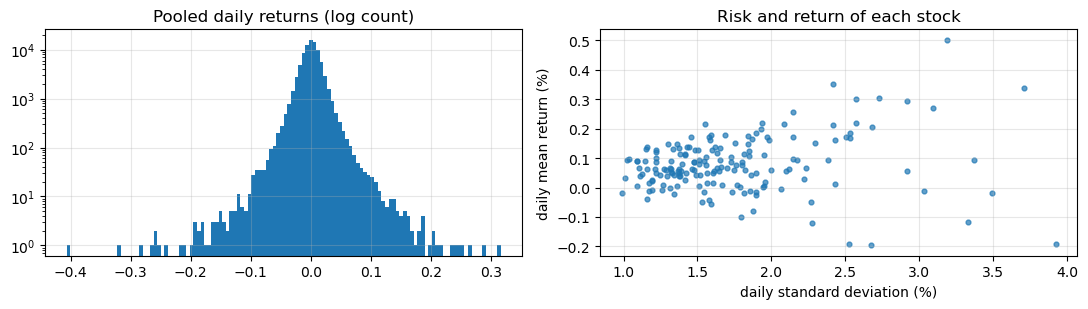

In [8]:
flat = returns_all.to_numpy().ravel()
print(f"daily return: mean = {flat.mean():.5f}, std = {flat.std():.4f}, min = {flat.min():.3f}, max = {flat.max():.3f}")
worst = returns_all.abs().stack().sort_values(ascending=False).head(5)
print("five largest absolute daily moves:")
print(worst.rename("abs return").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(flat, bins=120)
axes[0].set_yscale("log")
axes[0].set_title("Pooled daily returns (log count)")
axes[1].scatter(returns_all.std() * 100, returns_all.mean() * 100, s=12, alpha=0.7)
axes[1].set_xlabel("daily standard deviation (%)")
axes[1].set_ylabel("daily mean return (%)")
axes[1].set_title("Risk and return of each stock")
plt.tight_layout()
plt.show()

## 3. Mathematical formulation

**Sets and data.** Stocks $i = 1..N$, days $t = 1..T$. $r_{ti}$ is the simple return of stock $i$ on day $t$, $\mu_i$ its mean, `K`, $\ell$ (LOWER), $u$ (UPPER) and the return target $R^{*}$ as above.

**Decision variables.**
- $w_i \ge 0$: fraction of the money invested in stock $i$ (continuous)
- $z_i \in \{0,1\}$: 1 if stock $i$ is held (binary)
- $d_t \ge 0$: absolute deviation of the portfolio's return on day $t$ from its mean (continuous)

**Risk measure.** Mean absolute deviation (MAD) of the portfolio's daily return: $\frac{1}{T}\sum_t \left|\sum_i (r_{ti}-\mu_i)\,w_i\right|$. It is the L1 counterpart of variance (Lecture 2 slides 29-36). It is used because it keeps the model *linear*, so it stays a MILP.

$$\min \;\; \frac{1}{T}\sum_{t=1}^{T} d_t \tag{1}$$

subject to

$$d_t \;\ge\; \sum_{i}(r_{ti}-\mu_i)\,w_i \qquad d_t \;\ge\; -\sum_{i}(r_{ti}-\mu_i)\,w_i \qquad \forall t \tag{2, 3}$$
$$\sum_i \mu_i\, w_i \;\ge\; R^{*} \tag{4 return target}$$
$$\sum_i w_i = 1 \tag{5 budget}$$
$$\sum_i z_i \;\le\; K \tag{6 cardinality}$$
$$\ell\, z_i \;\le\; w_i \;\le\; u\, z_i \qquad \forall i \tag{7 link and bounds}$$

**Why it is linear.** Constraints (2)-(3) represent $|a|$ as $d \ge a$ and $d \ge -a$; minimising $d$ pushes it down to $|a|$ (the same idea as the free-variable split in Lecture 3 slides 22-28). Everything is linear, and only the $z_i$ are integer, so this is a MILP (Lecture 5 slides 7-9).

**Size.** $2N + T$ variables ($N$ binary) and $2T + 2N + 3$ constraints.

**Why the problem is hard.** Choosing $K$ of $N$ stocks gives $\binom{N}{K}$ subsets (Lecture 1 slides 36-39); cardinality-constrained portfolio selection is NP-hard (Lecture 1 slides 46-53), which is why a heuristic is worth comparing against.

## 4. Helper functions

- `mad`, `variance`: the two risk measures, used to evaluate any solution.
- `check_portfolio`: an **independent** feasibility check of every constraint, applied to every reported solution (we never trust the solver's own claim).
- `max_feasible_return`, `return_target`: build a return target that is demanding but reachable.
- `get_universe`: random set of N stocks with a fixed seed.

In [9]:
def mad(R, w):
    # mean absolute deviation of the portfolio's daily return
    R = np.asarray(R, float); w = np.asarray(w, float)
    return float(np.mean(np.abs((R - R.mean(axis=0)) @ w)))


def variance(R, w):
    w = np.asarray(w, float)
    return float(w @ np.cov(np.asarray(R, float), rowvar=False) @ w)


def check_portfolio(w, mu, k, lower, upper, target, tol=1e-6):
    # re-verify all constraints: budget, no shorting, cardinality, weight bounds, return target
    w = np.asarray(w, float); held = w > tol; problems = []
    if abs(w.sum() - 1) > tol:
        problems.append(f"weights sum to {w.sum():.8f}")
    if (w < -tol).any():
        problems.append("negative weight")
    if held.sum() > k:
        problems.append(f"{int(held.sum())} stocks held, limit {k}")
    if held.any() and (w[held] < lower - tol).any():
        problems.append("a held stock is below the minimum weight")
    if (w > upper + tol).any():
        problems.append("a weight exceeds the maximum")
    ret = float(np.asarray(mu) @ w)
    if ret < target - tol:
        problems.append(f"expected return {ret:.6f} below target {target:.6f}")
    return {"feasible": not problems, "problems": problems, "n_held": int(held.sum()), "expected_return": ret}


def max_feasible_return(mu, k, upper):
    # best expected return with at most k stocks, each weight <= upper (ignores the lower bound: slightly optimistic)
    remaining, total = 1.0, 0.0
    for m in np.sort(mu)[::-1][:k]:
        take = min(upper, remaining)
        total += take * m
        remaining -= take
    return total


def return_target(mu, k, upper, frac):
    base = float(np.mean(mu))                      # equal-weight return over the universe
    return base + frac * (max_feasible_return(mu, k, upper) - base)


def get_universe(n, seed):
    rng = np.random.default_rng(SEED + 1000 * seed + n)
    cols = sorted(rng.choice(returns_all.columns.to_numpy(), size=n, replace=False))
    return returns_all[cols]

## 5. The exact solver

`solve_mad_milp` builds the model (1)-(7) as sparse matrices and calls HiGHS via `scipy.optimize.milp`. With `integer=False` the same function solves the **LP relaxation** ($z_i$ allowed to be fractional), whose optimum is a valid **lower bound** for a minimisation problem (Lecture 5 slides 23-28). With `integer=True` it runs **Branch and Bound** (Lecture 5 slides 29-39) and reports the status, the best bound, the gap and the number of nodes.

Variable order in the vector `x`: `[w (N), z (N), d (T)]`.

In [10]:
STATUS = {0: "Optimal", 1: "Time limit", 2: "Infeasible", 3: "Unbounded", 4: "Other"}


def solve_mad_milp(R, k, lower, upper, target, integer=True, time_limit=60, rel_gap=1e-4):
    R = np.asarray(R, float)
    T, N = R.shape
    mu = R.mean(axis=0)
    D = sp.csr_matrix(R - mu)
    I_T, I_N = sp.identity(T, format="csr"), sp.identity(N, format="csr")
    zT, zN = sp.csr_matrix((T, N)), sp.csr_matrix((N, N))
    row = lambda a, b, c: sp.hstack([sp.csr_matrix(np.atleast_2d(a)), sp.csr_matrix(np.atleast_2d(b)), sp.csr_matrix(np.atleast_2d(c))])

    A = sp.vstack([
        sp.hstack([-D, zT, I_T]),                         # (2) d_t >=  D_t w
        sp.hstack([D, zT, I_T]),                          # (3) d_t >= -D_t w
        row(mu, np.zeros(N), np.zeros(T)),                # (4) return target
        row(np.ones(N), np.zeros(N), np.zeros(T)),        # (5) budget
        row(np.zeros(N), np.ones(N), np.zeros(T)),        # (6) cardinality
        sp.hstack([I_N, -lower * I_N, sp.csr_matrix((N, T))]),   # (7) w >= lower * z
        sp.hstack([I_N, -upper * I_N, sp.csr_matrix((N, T))]),   # (7) w <= upper * z
    ]).tocsr()
    lo = np.r_[np.zeros(2 * T), target, 1.0, -np.inf, np.zeros(N), np.full(N, -np.inf)]
    hi = np.r_[np.full(2 * T, np.inf), np.inf, 1.0, k, np.full(N, np.inf), np.zeros(N)]
    c = np.r_[np.zeros(2 * N), np.full(T, 1.0 / T)]
    integrality = np.r_[np.zeros(N), np.ones(N) if integer else np.zeros(N), np.zeros(T)]
    bounds = Bounds(np.zeros(2 * N + T), np.r_[np.ones(2 * N), np.full(T, np.inf)])

    t0 = time.perf_counter()
    res = milp(c, constraints=LinearConstraint(A, lo, hi), integrality=integrality, bounds=bounds,
               options={"time_limit": time_limit, "mip_rel_gap": rel_gap, "disp": False})
    elapsed = time.perf_counter() - t0

    w = res.x[:N] if res.x is not None else None
    w = np.where(w < 1e-9, 0.0, w) if w is not None else None
    return {"status": res.status, "status_text": STATUS.get(res.status, "Other"), "time": elapsed,
            "obj": res.fun if res.x is not None else np.nan,
            "bound": getattr(res, "mip_dual_bound", np.nan) if integer else (res.fun if res.x is not None else np.nan),
            "gap": getattr(res, "mip_gap", np.nan) if integer else np.nan,
            "nodes": getattr(res, "mip_node_count", np.nan) if integer else np.nan,
            "w": w, "mad": mad(R, w) if w is not None else np.nan,
            "n_vars": 2 * N + T, "n_cons": 2 * T + 2 * N + 3}

### 5.1 Worked example (N = 50)

One universe of 50 stocks: solve the LP relaxation, then the MILP, check feasibility independently, and look at which stocks were chosen (with sector from `df_companies`).

In [11]:
n_demo = min(50, N_ALL)
ret_demo = get_universe(n_demo, seed=0)
R = ret_demo.to_numpy(); mu = R.mean(axis=0)
target = return_target(mu, K, UPPER, TARGET_FRAC)

rel = solve_mad_milp(R, K, LOWER, UPPER, target, integer=False)
ex = solve_mad_milp(R, K, LOWER, UPPER, target, integer=True, time_limit=TIME_LIMIT, rel_gap=REL_GAP)
chk = check_portfolio(ex["w"], mu, K, LOWER, UPPER, target)

print(f"N = {n_demo}, T = {R.shape[0]}, K = {K}, return target = {target:.5f}  (model: {ex['n_vars']} variables, {ex['n_cons']} constraints)")
print(f"LP relaxation  : MAD = {rel['obj']:.6f}  ({rel['time']:.2f} s)   <- lower bound")
print(f"MILP (exact)   : MAD = {ex['mad']:.6f}  status = {ex['status_text']}, gap = {ex['gap']:.2e}, nodes = {ex['nodes']:.0f}, time = {ex['time']:.2f} s")
print(f"root gap (LP vs MILP) = {100 * (ex['mad'] - rel['obj']) / ex['mad']:.2f} %")
print("independent check:", chk)
assert chk["feasible"], "the exact solution failed the independent check"
assert abs(ex["obj"] - ex["mad"]) < 1e-6, "solver objective and recomputed MAD disagree"

held = np.flatnonzero(ex["w"] > 1e-6)
table = (pd.DataFrame({"Symbol": ret_demo.columns[held], "weight": ex["w"][held], "mean daily return": mu[held]})
         .merge(df_companies[["Symbol", "Shortname", "Sector"]], on="Symbol", how="left")
         .sort_values("weight", ascending=False).reset_index(drop=True))
table

N = 50, T = 499, K = 5, return target = 0.00250  (model: 599 variables, 1101 constraints)
LP relaxation  : MAD = 0.009429  (0.06 s)   <- lower bound
MILP (exact)   : MAD = 0.009500  status = Optimal, gap = 0.00e+00, nodes = 5, time = 4.91 s
root gap (LP vs MILP) = 0.75 %
independent check: {'feasible': True, 'problems': [], 'n_held': 5, 'expected_return': 0.0025032868759419674}


,Symbol,weight,mean daily return,Shortname,Sector
0,CME,0.30000,0.00090,CME Group Inc.,Financial Services
1,NVDA,0.29737,0.00502,NVIDIA Corporation,Technology
2,IRM,0.20013,0.00173,Iron Mountain Incorporated (Del,Real Estate
3,PH,0.12609,0.00179,Parker-Hannifin Corporation,Industrials
4,AMZN,0.07641,0.00219,"Amazon.com, Inc.",Consumer Cyclical


MAD = 0.009500 | variance = 1.605e-04 | daily std = 0.0127 | expected return = 0.00250


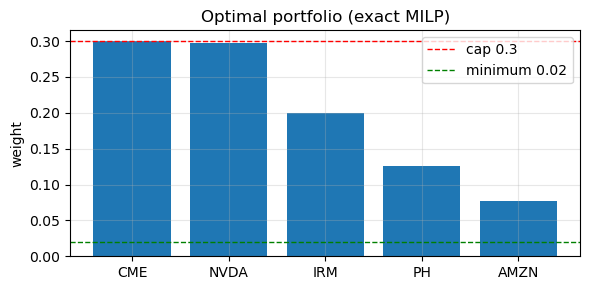

In [12]:
print(f"MAD = {ex['mad']:.6f} | variance = {variance(R, ex['w']):.3e} | daily std = {np.sqrt(variance(R, ex['w'])):.4f} | expected return = {chk['expected_return']:.5f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(table["Symbol"], table["weight"])
ax.axhline(UPPER, color="r", ls="--", lw=1, label=f"cap {UPPER}")
ax.axhline(LOWER, color="g", ls="--", lw=1, label=f"minimum {LOWER}")
ax.set_ylabel("weight"); ax.set_title("Optimal portfolio (exact MILP)"); ax.legend()
plt.tight_layout()
plt.show()

### 5.2 Validation against brute force

To be sure the MILP is correct, we solve a small case a second, independent way: enumerate **every** allowed subset of stocks, solve the continuous weight problem for each subset with a plain LP, and keep the best. The MILP must give the same optimum. We use a 12-stock universe. Subsets must contain at least $\lceil 1/u \rceil$ stocks because each weight is capped at $u$.

In [13]:
def best_weights_for_subset(R, idx, lower, upper, target):
    # LP over the weights of a fixed subset: min mean absolute deviation (all chosen stocks are held)
    T = R.shape[0]; k = len(idx)
    mu = R.mean(axis=0); D = (R - mu)[:, idx]
    c = np.r_[np.zeros(k), np.full(T, 1.0 / T)]
    A_ub = np.vstack([np.hstack([D, -np.eye(T)]), np.hstack([-D, -np.eye(T)]), np.r_[-mu[idx], np.zeros(T)][None, :]])
    b_ub = np.r_[np.zeros(2 * T), -target]
    A_eq = np.r_[np.ones(k), np.zeros(T)][None, :]
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0],
                  bounds=[(lower, upper)] * k + [(0, None)] * T, method="highs")
    return (res.fun, res.x[:k]) if res.status == 0 else (None, None)


n_val = 12
R12 = get_universe(n_val, seed=0).to_numpy(); mu12 = R12.mean(axis=0)
target12 = return_target(mu12, K, UPPER, TARGET_FRAC)

t0 = time.perf_counter()
best = (np.inf, None)
n_lp = 0
for size in range(int(np.ceil(1 / UPPER)), K + 1):
    for idx in combinations(range(n_val), size):
        n_lp += 1
        val, _ = best_weights_for_subset(R12, list(idx), LOWER, UPPER, target12)
        if val is not None and val < best[0]:
            best = (val, idx)
t_brute = time.perf_counter() - t0

ex12 = solve_mad_milp(R12, K, LOWER, UPPER, target12, integer=True, time_limit=TIME_LIMIT, rel_gap=1e-9)
print(f"brute force: {n_lp} LPs, best MAD = {best[0]:.8f}, subset = {best[1]}  ({t_brute:.1f} s)")
print(f"MILP       : best MAD = {ex12['mad']:.8f}, subset = {tuple(int(i) for i in np.flatnonzero(ex12['w'] > 1e-6))}  ({ex12['time']:.2f} s, {ex12['status_text']})")
assert abs(best[0] - ex12["mad"]) < 1e-6, "MILP and brute force disagree"
print("validation passed: both methods find the same optimum")

brute force: 1287 LPs, best MAD = 0.00705474, subset = (1, 2, 7, 10, 11)  (13.0 s)
MILP       : best MAD = 0.00705474, subset = (1, 2, 7, 10, 11)  (0.30 s, Optimal)
validation passed: both methods find the same optimum


## 6. Experiments

### 6.1 Scalability and the LP-relaxation gap

For each universe size and several random universes (seeds) we record: the proven status, runtime, best bound, MIP gap, number of Branch and Bound nodes, and how far the **root LP relaxation** is from the integer optimum (the *integrality gap*, Lecture 5 slides 23-28). Every solution goes through the independent checker. These rows are saved for the comparison with the heuristic.

Two configurations are run:

| Configuration | K | Return target | Purpose |
|---|---|---|---|
| `base` | 5 | `TARGET_FRAC` = 0.7 | The main study over all sizes and 3 random universes |
| `hard` | 8 | 0.5 | A configuration in which the exact solver is expected to be slow or to hit the time limit, so the heuristic has something to beat |

When N equals the number of complete stocks (the whole universe), every seed gives the identical problem, so it is run once.

In [14]:
CONFIGS = {
    "base": dict(k=K, frac=TARGET_FRAC, sizes=SIZES, seeds=SEEDS),
    "hard": dict(k=8, frac=0.5, sizes=[n for n in SIZES if n >= 100], seeds=SEEDS[:1]),
}
rows = []
for cfg_name, cfg in CONFIGS.items():
    k_c = cfg["k"]
    assert k_c * UPPER >= 1
    for n in cfg["sizes"]:
        for s in (cfg["seeds"] if n < N_ALL else cfg["seeds"][:1]):
            U = get_universe(n, s); R = U.to_numpy(); mu = R.mean(axis=0)
            target = return_target(mu, k_c, UPPER, cfg["frac"])
            rel = solve_mad_milp(R, k_c, LOWER, UPPER, target, integer=False)
            ex = solve_mad_milp(R, k_c, LOWER, UPPER, target, integer=True, time_limit=TIME_LIMIT, rel_gap=REL_GAP)
            chk = check_portfolio(ex["w"], mu, k_c, LOWER, UPPER, target) if ex["w"] is not None else {"feasible": False, "n_held": 0}
            rows.append(dict(config=cfg_name, N=n, seed=s, T=R.shape[0], K=k_c, target_frac=cfg["frac"], target=target,
                             status=ex["status_text"], objective_mad=ex["mad"],
                             best_bound=ex["bound"], mip_gap=ex["gap"], relax_mad=rel["obj"],
                             root_gap_pct=100 * (ex["mad"] - rel["obj"]) / ex["mad"] if ex["w"] is not None else np.nan,
                             runtime_s=ex["time"], nodes=ex["nodes"], n_held=chk["n_held"], feasible=chk["feasible"],
                             variance=variance(R, ex["w"]) if ex["w"] is not None else np.nan,
                             n_vars=ex["n_vars"], n_cons=ex["n_cons"],
                             selected=",".join(U.columns[np.flatnonzero(ex["w"] > 1e-6)]) if ex["w"] is not None else ""))
            print(f"[{cfg_name}] N={n:>3} seed={s} K={k_c}  {ex['status_text']:<10} MAD={ex['mad']:.6f}  gap={ex['gap']:.1e}  nodes={ex['nodes']:>6.0f}  {ex['time']:6.1f} s  feasible={chk['feasible']}", flush=True)
results = pd.DataFrame(rows)

[base] N= 20 seed=0 K=5  Optimal    MAD=0.007572  gap=0.0e+00  nodes=    72     1.8 s  feasible=True


[base] N= 20 seed=1 K=5  Optimal    MAD=0.007344  gap=0.0e+00  nodes=     1     0.8 s  feasible=True


[base] N= 20 seed=2 K=5  Optimal    MAD=0.007484  gap=0.0e+00  nodes=     1     1.1 s  feasible=True


[base] N= 50 seed=0 K=5  Optimal    MAD=0.009500  gap=0.0e+00  nodes=     5     5.4 s  feasible=True


[base] N= 50 seed=1 K=5  Optimal    MAD=0.008043  gap=0.0e+00  nodes=    41     3.4 s  feasible=True


...

[base] N=100 seed=1 K=5  Optimal    MAD=0.009462  gap=0.0e+00  nodes=     9     9.2 s  feasible=True


[base] N=100 seed=2 K=5  Optimal    MAD=0.008489  gap=0.0e+00  nodes=    83    10.5 s  feasible=True


[base] N=170 seed=0 K=5  Optimal    MAD=0.009741  gap=0.0e+00  nodes=     7    28.0 s  feasible=True


[hard] N=100 seed=0 K=8  Optimal    MAD=0.007236  gap=0.0e+00  nodes=    29    11.9 s  feasible=True


[hard] N=170 seed=0 K=8  Time limit MAD=0.007195  gap=9.4e-03  nodes=   356    60.0 s  feasible=True


In [15]:
summary = (results.groupby(["config", "N"])
           .agg(instances=("seed", "count"), proven_optimal=("status", lambda s: int((s == "Optimal").sum())),
                median_runtime_s=("runtime_s", "median"), max_runtime_s=("runtime_s", "max"),
                median_nodes=("nodes", "median"), mean_mip_gap=("mip_gap", "mean"), mean_root_gap_pct=("root_gap_pct", "mean"),
                mean_objective_mad=("objective_mad", "mean"), all_feasible=("feasible", "all"),
                n_vars=("n_vars", "first"), n_cons=("n_cons", "first")))
summary

instances  proven_optimal  median_runtime_s  max_runtime_s  median_nodes  mean_mip_gap  mean_root_gap_pct  mean_objective_mad  \
config N                                                                                                                                    
base   20           3               3           1.12806        1.82982           1.0       0.00000            1.73038             0.00747   
       50           3               3           3.96526        5.44222           5.0       0.00000            2.02391             0.00903   
       100          3               3          10.49130       10.63831          11.0       0.00000            1.79290             0.00920   
       170          1               1          27.99689       27.99689           7.0       0.00000            1.80452             0.00974   
hard   100          1               1          11.90458       11.90458          29.0       0.00000            0.65154             0.00724   
       170          1               0          60.04190       60.04190         356.0       0.00941            1.62610             0.00720   

            all_feasible  n_vars  n_cons  
config N                                  
base   20           True     539    1041  
       50           True     599    1101  
       100          True     699    1201  
       170          True     839    1341  
hard   100          True     699    1201  
       170          True     839    1341

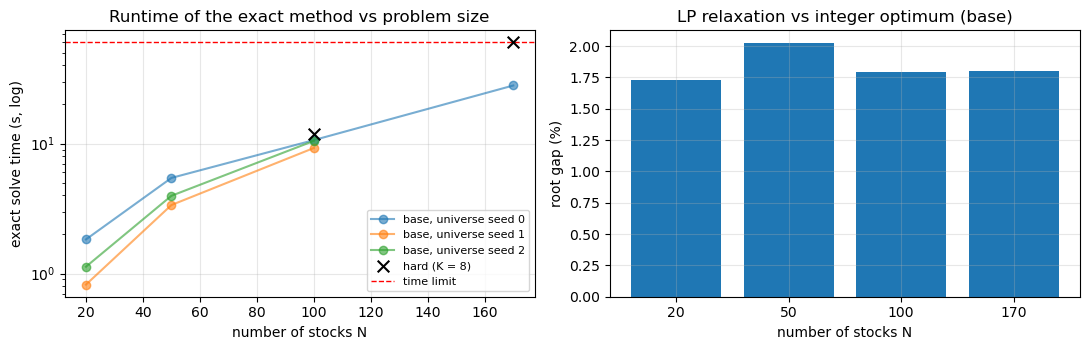

In [16]:
base = results[results.config == "base"]
hard = results[results.config == "hard"]
sb = summary.loc["base"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for s, g in base.groupby("seed"):
    axes[0].plot(g["N"], g["runtime_s"], "o-", alpha=0.6, label=f"base, universe seed {s}")
if len(hard):
    axes[0].scatter(hard["N"], hard["runtime_s"], marker="x", s=70, color="k", label="hard (K = 8)", zorder=5)
axes[0].axhline(TIME_LIMIT, color="r", ls="--", lw=1, label="time limit")
axes[0].set_yscale("log"); axes[0].set_xlabel("number of stocks N"); axes[0].set_ylabel("exact solve time (s, log)")
axes[0].set_title("Runtime of the exact method vs problem size"); axes[0].legend(fontsize=8)
axes[1].bar([str(n) for n in sb.index], sb["mean_root_gap_pct"])
axes[1].set_xlabel("number of stocks N"); axes[1].set_ylabel("root gap (%)")
axes[1].set_title("LP relaxation vs integer optimum (base)")
plt.tight_layout()
plt.show()

### 6.2 Effect of the cardinality limit K

A larger K allows more diversification (lower risk) but changes how hard the search is. We measure both. The return target is fixed across the sweep (built for the smallest K) so the runs are comparable.

In [17]:
n_k = min(100, N_ALL)
R = get_universe(n_k, 0).to_numpy(); mu = R.mean(axis=0)
Ks = [k for k in (4, 5, 8, 10) if k * UPPER >= 1]
target_k = return_target(mu, min(Ks), UPPER, TARGET_FRAC)
rows_k = []
for k in Ks:
    ex = solve_mad_milp(R, k, LOWER, UPPER, target_k, integer=True, time_limit=TIME_LIMIT, rel_gap=REL_GAP)
    chk = check_portfolio(ex["w"], mu, k, LOWER, UPPER, target_k)
    rows_k.append(dict(K=k, status=ex["status_text"], objective_mad=ex["mad"], best_bound=ex["bound"], mip_gap=ex["gap"],
                       runtime_s=ex["time"], nodes=ex["nodes"], n_held=chk["n_held"], feasible=chk["feasible"]))
    print(f"K={k:>2}  {ex['status_text']:<10} MAD={ex['mad']:.6f}  gap={ex['gap']:.1e}  {ex['time']:6.1f} s", flush=True)
k_table = pd.DataFrame(rows_k)
k_table

K= 4  Optimal    MAD=0.009786  gap=0.0e+00    17.2 s


K= 5  Optimal    MAD=0.009664  gap=0.0e+00    12.2 s


K= 8  Optimal    MAD=0.009577  gap=0.0e+00     4.0 s


K=10  Optimal    MAD=0.009566  gap=1.7e-05     2.3 s


,K,status,objective_mad,best_bound,mip_gap,runtime_s,nodes,n_held,feasible
0,4,Optimal,0.00979,0.00979,0.00000,17.18308,14,4,True
1,5,Optimal,0.00966,0.00966,0.00000,12.20956,11,5,True
2,8,Optimal,0.00958,0.00958,0.00000,3.98541,13,8,True
3,10,Optimal,0.00957,0.00957,0.00002,2.29709,1,10,True


### 6.3 Efficient frontier and the price of the cardinality limit

We sweep the return target and solve the exact model each time (K stocks), and compare with the same problem **without** a cardinality limit (a pure LP, `K = N`, no minimum weight). The gap between the two curves is the cost, in extra risk, of holding only K stocks.

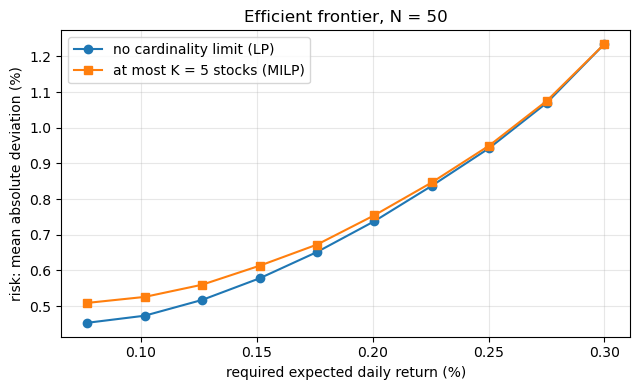

,target,mad_free,mad_K,extra_risk_pct,held,status
0,0.00077,0.00453,0.00509,1.23147e+01,5,Optimal
1,0.00102,0.00473,0.00526,1.11392e+01,5,Optimal
2,0.00126,0.00517,0.00560,8.24872e+00,5,Optimal
3,0.00151,0.00578,0.00613,6.10585e+00,5,Optimal
4,0.00176,0.00651,0.00672,3.19392e+00,5,Optimal
5,0.00201,0.00738,0.00755,2.25562e+00,5,Optimal
6,0.00226,0.00837,0.00847,1.12602e+00,5,Optimal
7,0.00250,0.00943,0.00950,7.51144e-01,5,Optimal
8,0.00275,0.01070,0.01075,5.14244e-01,5,Optimal
9,0.00300,0.01234,0.01234,2.22045e-14,5,Optimal


In [18]:
n_f = min(50, N_ALL)
R = get_universe(n_f, 0).to_numpy(); mu = R.mean(axis=0)
fracs = np.linspace(0.0, 0.9, 10)
fr = []
for f in fracs:
    tg = return_target(mu, K, UPPER, f)
    e = solve_mad_milp(R, K, LOWER, UPPER, tg, integer=True, time_limit=TIME_LIMIT, rel_gap=REL_GAP)
    u = solve_mad_milp(R, n_f, 0.0, UPPER, tg, integer=False)          # no cardinality limit: pure LP
    fr.append(dict(frac=f, target=tg, mad_K=e["mad"], mad_free=u["obj"], status=e["status_text"], held=int((e["w"] > 1e-6).sum())))
frontier = pd.DataFrame(fr)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(frontier["target"] * 100, frontier["mad_free"] * 100, "o-", label="no cardinality limit (LP)")
ax.plot(frontier["target"] * 100, frontier["mad_K"] * 100, "s-", label=f"at most K = {K} stocks (MILP)")
ax.set_xlabel("required expected daily return (%)"); ax.set_ylabel("risk: mean absolute deviation (%)")
ax.set_title(f"Efficient frontier, N = {n_f}"); ax.legend()
plt.tight_layout()
plt.show()
frontier.assign(extra_risk_pct=100 * (frontier["mad_K"] / frontier["mad_free"] - 1))[["target", "mad_free", "mad_K", "extra_risk_pct", "held", "status"]]

### 6.4 Naive baselines (what optimisation buys)

Two simple reference portfolios on the same universes and the same constraints (base configuration): (a) the **K stocks with the highest mean return, equal weight**, and (b) **random K-stock** equal-weight portfolios. These are not the heuristic of the assignment, only a yardstick.

**Read the table carefully.** The top-K portfolio meets the return target, so its risk is comparable with the exact optimum. The random portfolios almost never meet the return target, so their lower average risk is *not* comparable: they achieve it by earning less than required. The column `random_K_meets_target_pct` shows how rarely they are feasible.

In [19]:
rng = np.random.default_rng(SEED)
rows_b = []
for n in SIZES:
    R = get_universe(n, 0).to_numpy(); mu = R.mean(axis=0)
    target = return_target(mu, K, UPPER, TARGET_FRAC)
    opt = float(results[(results.config == "base") & (results.N == n) & (results.seed == 0)]["objective_mad"].iloc[0])
    w_top = np.zeros(n); w_top[np.argsort(mu)[::-1][:K]] = 1.0 / K
    ok_top = check_portfolio(w_top, mu, K, LOWER, UPPER, target)["feasible"]
    rand_mad, rand_ok = [], 0
    for _ in range(300):
        w = np.zeros(n); w[rng.choice(n, K, replace=False)] = 1.0 / K
        rand_mad.append(mad(R, w)); rand_ok += check_portfolio(w, mu, K, LOWER, UPPER, target)["feasible"]
    rows_b.append(dict(N=n, exact_mad=opt, topK_mad=mad(R, w_top), topK_feasible=ok_top,
                       topK_worse_than_exact_pct=100 * (mad(R, w_top) / opt - 1),
                       random_K_mean_mad_ignoring_target=float(np.mean(rand_mad)), random_K_meets_target_pct=100 * rand_ok / 300))
baselines = pd.DataFrame(rows_b).set_index("N")
baselines

,exact_mad,topK_mad,topK_feasible,topK_worse_than_exact_pct,random_K_mean_mad_ignoring_target,random_K_meets_target_pct
N,,,,,,
20,0.00757,0.00951,True,25.65969,0.00808,1.33333
50,0.00950,0.01348,True,41.88440,0.00867,0.00000
100,0.00966,0.01361,True,40.85518,0.00835,0.00000
170,0.00974,0.01432,True,46.96328,0.00835,0.00000


## 7. Saved results

The exact-method results are written to `results/exact_results.csv`. The heuristic methods will be compared against these rows: **same universes** (`get_universe(N, seed)`), **same K, bounds and target rule** (the `config` column says whether a row is `base` or `hard`), and the same MAD objective.

In [20]:
out_dir = Path("results")
out_dir.mkdir(exist_ok=True)
results.to_csv(out_dir / "exact_results.csv", index=False)
print("saved", out_dir / "exact_results.csv", "|", len(results), "rows")
print("parameters:", dict(WINDOW_ROWS=WINDOW_ROWS, K=K, LOWER=LOWER, UPPER=UPPER, TARGET_FRAC=TARGET_FRAC,
                          TIME_LIMIT=TIME_LIMIT, REL_GAP=REL_GAP, SEED=SEED, SEEDS=SEEDS, SIZES=SIZES))
results.drop(columns=["selected"]).head(12)

saved results\exact_results.csv | 12 rows
parameters: {'WINDOW_ROWS': 500, 'K': 5, 'LOWER': 0.02, 'UPPER': 0.3, 'TARGET_FRAC': 0.7, 'TIME_LIMIT': 60, 'REL_GAP': 0.0001, 'SEED': 42, 'SEEDS': [0, 1, 2], 'SIZES': [20, 50, 100, 170]}


,config,N,seed,T,K,target_frac,target,status,objective_mad,best_bound,mip_gap,relax_mad,root_gap_pct,runtime_s,nodes,n_held,feasible,variance,n_vars,n_cons
0,base,20,0,499,5,0.7,0.00150,Optimal,0.00757,0.00757,0.00000,0.00731,3.49502,1.82982,72,5,True,0.00009,539,1041
1,base,20,1,499,5,0.7,0.00130,Optimal,0.00734,0.00734,0.00000,0.00725,1.27950,0.82150,1,5,True,0.00009,539,1041
2,base,20,2,499,5,0.7,0.00179,Optimal,0.00748,0.00748,0.00000,0.00745,0.41663,1.12806,1,5,True,0.00011,539,1041
3,base,50,0,499,5,0.7,0.00250,Optimal,0.00950,0.00950,0.00000,0.00943,0.74554,5.44222,5,5,True,0.00016,599,1101
4,base,50,1,499,5,0.7,0.00192,Optimal,0.00804,0.00804,0.00000,0.00770,4.28649,3.36631,41,5,True,0.00012,599,1101
5,base,50,2,499,5,0.7,0.00288,Optimal,0.00956,0.00956,0.00000,0.00946,1.03969,3.96526,5,5,True,0.00017,599,1101
6,base,100,0,499,5,0.7,0.00284,Optimal,0.00966,0.00966,0.00000,0.00957,1.02402,10.63831,11,5,True,0.00018,699,1201
7,base,100,1,499,5,0.7,0.00285,Optimal,0.00946,0.00946,0.00000,0.00933,1.42980,9.24970,9,5,True,0.00016,699,1201
8,base,100,2,499,5,0.7,0.00243,Optimal,0.00849,0.00849,0.00000,0.00824,2.92488,10.49130,83,5,True,0.00014,699,1201
9,base,170,0,499,5,0.7,0.00296,Optimal,0.00974,0.00974,0.00000,0.00956,1.80452,27.99689,7,5,True,0.00018,839,1341


## 8. Findings (exact method)

All numbers below come from the executed cells above (window 2022-12-27 to 2024-12-20, T = 499 daily returns, K = 5, weights 0.02 to 0.30, return target 70 % of the way to the best feasible return, MAD risk).

1. **Only 172 of the 502 listed symbols have any price data** (330 have none; 67.3 % of price rows are empty). 170 of them have a complete history in the window, so the largest universe is **170 stocks**, not 500.
2. **The MILP is correct.** On a 12-stock universe, brute force over all 1,287 allowed subsets (one LP each) and the MILP give the same optimum (MAD 0.00705474) and the same subset. Every reported solution also passes the independent feasibility check.
3. **Base configuration: everything is solved to proven optimality.** Median runtime grows with problem size: 1.1 s (N = 20), 4.0 s (N = 50), 10.5 s (N = 100), 28.0 s (N = 170, the whole universe). Branch and Bound needs few nodes (median 1 to 11, at most 83).
4. **The LP relaxation is tight.** The root gap between the relaxation and the integer optimum is 0.4 % to 4.3 % per instance (mean 1.7 % to 2.0 % per size). This is why Branch and Bound closes it quickly (Lecture 5 slides 23-39). Consequence for the comparison: in this regime the exact method is practical, so a heuristic has to justify itself by **speed** and by behaviour on harder settings, not by the exact method being impossible.
5. **Hard configuration (K = 8, lower return target).** N = 100 is still solved in 11.9 s, but at **N = 170 the solver hits the 60 s limit** with 356 nodes and a **0.94 % gap** (best MAD found 0.007195). This is the one case where optimality is not proven, so a heuristic's result there is compared against the best bound.
6. **Effect of K (N = 100).** Risk falls with diminishing returns: MAD 0.009786 (K = 4), 0.009664 (5), 0.009577 (8), 0.009566 (10). Solve time falls too (17.2 s, 12.2 s, 4.0 s, 2.3 s) because a larger K makes the cardinality limit bind less; with K = 10 the problem is essentially solved at the root.
7. **Price of the cardinality limit (N = 50, K = 5).** Compared with the same problem without a cardinality limit, holding only 5 stocks costs 12.3 % more risk at the lowest return target, shrinking to about 0 % at the highest, because a high return target forces concentration in a few high-return stocks anyway.
8. **What optimisation buys.** The 5 highest-return stocks in equal weight meet the return target but carry 26 % to 47 % more risk than the exact optimum. Random 5-stock portfolios meet the return target in only 0 % to 1.3 % of draws.
9. **Example portfolio (N = 50).** CME 30.0 %, NVDA 29.7 %, IRM 20.0 %, PH 12.6 %, AMZN 7.6 %: five different sectors; MAD 0.0095.

**Limits and threats to validity.** One time window and in-sample risk only (no out-of-sample test); MAD instead of variance (chosen to keep the model linear); survivorship bias (only current index members, and only the 172 with prices); the return target depends on the universe, so targets are not comparable across N; runtimes are from one machine with a 60 s limit and relative gap 1e-4; the modelling constants (K, bounds, target rule) are assumptions.

**Future work.** Out-of-sample backtest, variance as an alternative risk (a mixed-integer quadratic model), stronger formulations or a commercial solver for harder settings, transaction costs and sector limits.

## 9. Hand-over to the heuristic notebook

The heuristic must be compared on **identical inputs**:

| Item | Rule |
|---|---|
| Data | the same `returns_all` (window 2022-12-27 to 2024-12-20, simple returns of the 170 complete stocks) |
| Universes | `get_universe(N, seed)` with `SEED = 42` for `N in [20, 50, 100, 170]`; seeds 0, 1, 2 (N = 170 only once) |
| Constraints | K stocks at most, weights between `LOWER` and `UPPER`, budget 1, expected return at least `target` |
| Targets | `return_target(mu, K, UPPER, frac)` with `frac = 0.7` (base, K = 5) and `frac = 0.5` (hard, K = 8) |
| Objective | mean absolute deviation `mad(R, w)` (also report `variance`) |
| Feasibility | every solution through `check_portfolio` |
| Reference | `results/exact_results.csv` (columns include `config, N, seed, K, target, status, objective_mad, best_bound, mip_gap, runtime_s, nodes, selected`) |

Gap of a heuristic result: `100 * (heuristic_mad - exact_mad) / exact_mad`. Where the exact status is `Time limit` (hard, N = 170), also report the gap to `best_bound`.